# Variational Autoencoder (VAE) for Prescription Images

## Project: AI-Based Prescription Understanding, Medicine Retrieval and Privacy-Preserving System

This notebook contains the **VAE (Variational Autoencoder)** module of the overall project.

**What this notebook demonstrates:**

1. **Reconstruction** — the VAE encodes a real handwritten prescription image into a latent
   probability distribution and decodes it back into an image that looks like the original.
2. **Generation** — the VAE decoder can also take a **randomly sampled** latent vector
   (with no real image behind it) and turn it into a **new, synthetic, prescription-like image**.

This second capability (generation from random noise) is what separates a VAE from a plain
AutoEncoder, and it is the core contribution shown here.

```
Prescription Image
       |
     Encoder
       |
  mu (mean) + log(variance)
       |
Reparameterization Trick
       |
  Latent Vector z
       |
     Decoder
       |
Reconstructed Image
```

```
Random latent vector z ~ N(0, I)
       |
     Decoder
       |
New synthetic prescription-like image
```

**Important:** the images generated by this VAE are **synthetic** (statistically plausible,
not real). They are used for research, demonstration, and privacy-preserving experimentation —
never presented as real or clinically valid prescriptions.


## 0. What Changed in This Version, and Why

### v3 diagnosis: outputs are blank, not blurry

Running the v2 notebook (the version this file was previously called) for the full 150 epochs
produces reconstructions and random samples that are essentially **flat gray rectangles with
no handwriting at all** — not just blurry, but empty. Looking at the actual training log makes
the cause clear:

```
Epoch 1/150   train_recon: 0.6663
Epoch 5/150   train_recon: 0.4854
Epoch 20/150  train_recon: 0.4489
Epoch 150/150 train_recon: 0.4510   <- basically unchanged for the last ~140 epochs
```

The reconstruction loss drops fast for a few epochs, then **flatlines** for the rest of
training. That is the signature of the decoder finding a lazy local minimum and giving up:
since a prescription image is >90% blank white page and only a thin fraction of pixels are
actual ink, a plain pixel/SSIM/perceptual loss can get a deceptively low score by predicting a
near-uniform light-gray image everywhere and never bothering to draw strokes. Once the decoder
settles there, gradients pointing toward "draw actual ink" are tiny compared to gradients that
just fine-tune the background shade, so it never escapes. Three things made that lazy minimum
especially easy to fall into and easy to get stuck in:

1. **Extreme foreground/background imbalance is not accounted for.** L1, SSIM and the VGG
   perceptual loss all treat every pixel equally, so the (uninformative) white background
   dominates the loss even though the (informative) ink strokes are what actually matters.
2. **The latent bottleneck is far too small for the task.** A 256x256 image was compressed into
   a single 128-number vector — about 512x smaller than the input. That's an extremely tight
   bottleneck for reproducing detailed handwriting, and it gives the decoder very little to
   work with even if it wanted to draw strokes.
3. **All four reconstruction-loss terms (including the VGG perceptual loss) were active from
   epoch 1.** Perceptual/edge losses are only meaningful once the decoder can already produce
   *some* fine detail; turned on immediately, on top of a decoder that starts out only able to
   draw blurry blobs anyway, they mostly reinforce "stay blurry and safe" rather than pushing
   toward sharp strokes.

**Fixes applied in this version:**

| Problem | Fix |
|---|---|
| Background pixels dominate the reconstruction loss, so predicting blank pages is "cheap" | **Ink-weighted L1 loss** — dark (ink) target pixels are weighted several times higher than white background pixels, so getting the strokes wrong actually costs the model something |
| 128-dim flat vector bottleneck is too small to hold enough information for 256x256 handwriting | **Spatial latent**: encoder now outputs an `(latent_channels, 8, 8)` grid instead of one flat vector — ~16x more latent capacity, while still supporting pure-noise sampling for generation |
| Perceptual/edge losses push toward "safe" blur before the decoder can draw any detail | **Curriculum weighting**: perceptual + edge loss terms ramp in gradually over the first part of training instead of being at full strength from step 1 |
| A subset of latent dimensions can be pushed to exactly match the prior (posterior collapse) even with tiny KL weight | **Free bits**: each latent dimension's KL contribution is floored at a small positive value, so KL pressure can't fully zero out any dimension's usable information |
| Training silently wastes 150 epochs on a collapsed model before anyone notices | **Periodic preview grid**: every few epochs, a handful of validation reconstructions are saved and shown at the end, so a collapse is visible in the *first* 10-20 epochs instead of only after the full run |

### What v2 already fixed (kept as-is here)

The previous version fixed a different, earlier failure (blurry-but-present output). Those
fixes are unrelated to the collapse above and are kept unchanged:

| Problem | Likely cause | Fix applied |
|---|---|---|
| Reconstructions have a faint grid / checkerboard pattern | `ConvTranspose2d(kernel=4, stride=2)` in the decoder | Replaced with **`Upsample(nearest)` + `Conv2d`** |
| Random samples looked like pure noise | KL weight fixed near zero, latent space never organised | **Cyclical KL annealing** |
| Samples inconsistent between runs | `BatchNorm` statistics unstable in `eval()` | Replaced with **`GroupNorm`** |
| Occasional broken samples from extreme latent values | Full `N(0, I)` sampling includes poorly-decoded tails | **Truncation trick**, `tau ~= 0.85` |
| Quality bounces epoch to epoch | Only raw, oscillating weights used | **EMA** of the weights |
| Small dataset limits generalisation | No augmentation | Light **train-time augmentation** |
| Hard to tell if training converged | No validation signal | **Train/val split** + early-stopping option |

Everything else (dataset loading, preprocessing pipeline, overall notebook structure) is kept
the same, since that part was already working correctly.


## 1. Libraries and Setup

Import dependencies, detect GPU/CPU, and fix random seeds so results are reproducible.


In [1]:
import os
import copy
import zipfile
import time
import random

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.models import vgg16, VGG16_Weights

from sklearn.model_selection import train_test_split

print("PyTorch:", torch.__version__)

# -------------------------------------------------------
# Reproducibility
# -------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------------------------------------
# GPU detection
# -------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected - training will use CPU and may be slow. "
          "In Colab, go to Runtime > Change runtime type > GPU.")


PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


## 2. Dataset Loading

Upload the `RxHandBD-ML` dataset ZIP file and extract it. This section is unchanged because it
was already correct.


In [2]:
from google.colab import files

uploaded = files.upload()

zip_files = [name for name in uploaded.keys() if name.lower().endswith(".zip")]

assert len(zip_files) > 0, "Please upload the RxHandBD-ML ZIP file."

ZIP_PATH = os.path.join("/content", zip_files[0])

print("ZIP file:")
print(ZIP_PATH)

Saving RxHandBD-ML.zip to RxHandBD-ML.zip
ZIP file:
/content/RxHandBD-ML.zip


In [3]:
EXTRACT_DIR = "/content/RxHandBD"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extracted to:", EXTRACT_DIR)


Extracted to: /content/RxHandBD


In [4]:
TRAIN_DIR = None
TEST_DIR = None

for root, dirs, files_list in os.walk(EXTRACT_DIR):
    if "Train_Set" in dirs:
        TRAIN_DIR = os.path.join(root, "Train_Set")
    if "Test_Set" in dirs:
        TEST_DIR = os.path.join(root, "Test_Set")

print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)

assert TRAIN_DIR is not None, "Train_Set was not found."
assert TEST_DIR is not None, "Test_Set was not found."


Train: /content/RxHandBD/RxHandBD-ML/Train_Set
Test : /content/RxHandBD/RxHandBD-ML/Test_Set


## 3. Dataset Inspection

Before assuming anything about the data, inspect what is actually on disk: file counts, file
types, and a few raw image sizes.


In [5]:
def list_image_files(directory):
    found = []
    for root, dirs, files_list in os.walk(directory):
        for file in files_list:
            if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                found.append(os.path.join(root, file))
    return sorted(found)


train_files_preview = list_image_files(TRAIN_DIR)
test_files_preview = list_image_files(TEST_DIR)

print("Train images found:", len(train_files_preview))
print("Test images found :", len(test_files_preview))

print("\nRaw image sizes (before preprocessing):")
for path in train_files_preview[:5]:
    with Image.open(path) as im:
        print(os.path.basename(path), "->", im.size, im.mode)


Train images found: 4463
Test images found : 1115

Raw image sizes (before preprocessing):
P1116.jpg -> (512, 512) RGB
P1117.jpg -> (512, 512) RGB
P1118.jpg -> (512, 512) RGB
P1119.jpg -> (512, 512) RGB
P1120.jpg -> (512, 512) RGB


## 4. Image Preprocessing (+ Light Train-Time Augmentation)

`IMAGE_SIZE` and the core pipeline (grayscale, resize to 256x256, scale to `[0, 1]`) are kept
exactly as before.

**New:** `PrescriptionDataset` now takes an `augment` flag. When `True` (used for the training
split only — never for validation/test), it applies a small random rotation, a small random
translation, and mild brightness/contrast jitter *before* the image is turned into a tensor.
This is intentionally subtle (a few degrees / a few percent) — handwriting datasets are small,
so a little augmentation helps the model generalise instead of memorising exact strokes,
without distorting the images enough to teach it wrong shapes. `fill=255` assumes a white/light
paper background; change it if your scans use a different background value.


In [6]:
IMAGE_SIZE = 256  # unchanged

TRAIN_AUGMENTATION = transforms.Compose([
    transforms.RandomAffine(degrees=3, translate=(0.02, 0.02), fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
])


class PrescriptionDataset(Dataset):

    def __init__(self, directory, augment=False):
        self.files = []

        for root, dirs, files_list in os.walk(directory):
            for file in files_list:
                if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                    self.files.append(os.path.join(root, file))

        self.files.sort()
        self.augment = augment

        print(directory, "->", len(self.files), "images",
              "(augmented)" if augment else "(plain)")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        image = Image.open(self.files[index]).convert("L")  # grayscale
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)

        if self.augment:
            image = TRAIN_AUGMENTATION(image)

        image = np.asarray(image, dtype=np.float32) / 255.0
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)  # shape: (1, H, W)

        # target == input: the VAE reconstructs the same image it was given
        return image, image


## 5. Data Loaders, Train/Val Split, and Sample Images

**New:** a small validation split (10%) is carved out of the training set so training progress
can be monitored on unseen-but-representative data (used for early stopping below). The
validation split reuses the *non-augmented* dataset so it reflects real image quality. The test
set is untouched and still only used for the final reconstruction demo.


In [7]:
full_train_plain = PrescriptionDataset(TRAIN_DIR, augment=False)
full_train_aug = PrescriptionDataset(TRAIN_DIR, augment=True)
test_dataset = PrescriptionDataset(TEST_DIR, augment=False)

all_indices = list(range(len(full_train_plain)))
train_idx, val_idx = train_test_split(all_indices, test_size=0.1, random_state=SEED)

train_dataset = Subset(full_train_aug, train_idx)
val_dataset = Subset(full_train_plain, val_idx)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available(), drop_last=True,
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available(),
)

print("Training images  :", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images   :", len(test_dataset))


/content/RxHandBD/RxHandBD-ML/Train_Set -> 4463 images (plain)
/content/RxHandBD/RxHandBD-ML/Train_Set -> 4463 images (augmented)
/content/RxHandBD/RxHandBD-ML/Test_Set -> 1115 images (plain)
Training images  : 4016
Validation images: 447
Testing images   : 1115


Batch tensor shape: torch.Size([32, 1, 256, 256])


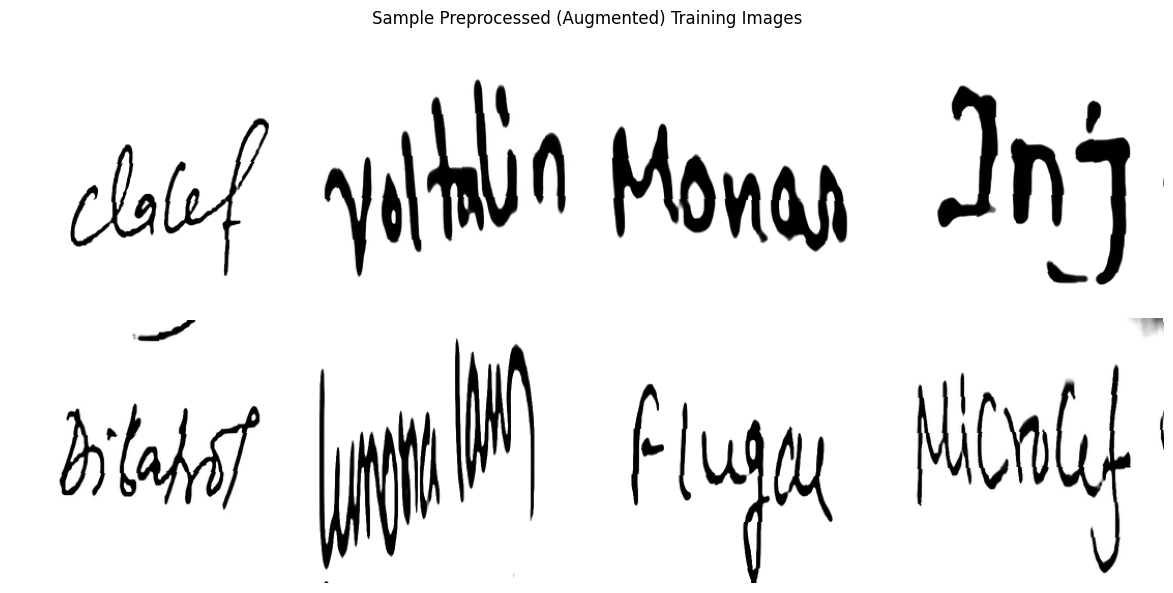

In [8]:
images, _ = next(iter(train_loader))

print("Batch tensor shape:", images.shape)  # (batch, 1, 256, 256)

plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Sample Preprocessed (Augmented) Training Images")
plt.tight_layout()
plt.show()


## 6. VAE Architecture — How It Works

A **plain AutoEncoder** learns a single fixed point in latent space for each image. A
**Variational Autoencoder (VAE)** instead learns a *distribution* over latent space, which is
what makes it capable of generating new images.

**Encoder** — turns an image into two grids that describe a distribution:
- **mu (mean)** — the centre of the distribution for this image in latent space
- **log_var (log variance)** — how spread out that distribution is

**Sampling (Reparameterization Trick)** — instead of using `mu` directly, we sample a point
near it:

```
sigma = exp(0.5 * log_var)
epsilon ~ N(0, 1)          (random noise)
z = mu + sigma * epsilon
```

**Decoder** — turns a latent `z` back into an image. It could be:
- a `z` sampled near a real image's `mu` (this gives **reconstruction**), or
- a `z` sampled from pure random noise `N(0, I)` (this gives **generation** of a brand-new
  synthetic image).

**Architecture changes in this version (see Section 0 for the reasoning):**
- `BatchNorm2d` -> `GroupNorm` throughout (encoder, decoder, residual blocks)
- Decoder upsampling: `ConvTranspose2d` -> `Upsample(nearest) + Conv2d` (removes checkerboard
  artifacts)
- **New:** the latent is a **spatial grid** `(latent_channels, 8, 8)` instead of a single flat
  128-length vector — produced with `1x1` convolutions instead of a `Linear` layer, so no
  spatial information has to be squeezed through one narrow bottleneck
- `z_log_var` is clamped to `[-10, 10]` for numerical stability


## 7. Encoder

Stack of strided convolutions (each halves the spatial size), `GroupNorm` instead of
`BatchNorm`, two residual blocks at the bottleneck, then two `1x1` convolutions producing a
*spatial* `z_mean` and `z_log_var` grid (shape `(latent_channels, 8, 8)`) instead of flattening
everything into one vector.


In [9]:
class ResidualBlock(nn.Module):
    """Two conv layers with a skip connection and GroupNorm.
    GroupNorm (unlike BatchNorm) does not depend on batch statistics, which makes
    behaviour more consistent between training and later generation from random z."""

    def __init__(self, channels, num_groups=8):
        super().__init__()

        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.gn1 = nn.GroupNorm(num_groups, channels)

        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.gn2 = nn.GroupNorm(num_groups, channels)

        self.activation = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.gn1(out)
        out = self.activation(out)

        out = self.conv2(out)
        out = self.gn2(out)

        out = out + residual  # skip connection
        out = self.activation(out)

        return out


class VAEEncoder(nn.Module):
    """
    Image -> feature map -> SPATIAL (z_mean, z_log_var)

    Unlike the previous version, the latent is NOT flattened into a single vector.
    Compressing a 256x256 image all the way down to 128 numbers is an extremely tight
    bottleneck: the decoder doesn't have enough information left to reproduce fine pen
    strokes, so it falls back to predicting the "safest" average image (a blank gray
    rectangle) - exactly the collapse described in Section 0.

    Instead, the latent keeps a small spatial map of shape (latent_channels, 8, 8). Every
    one of the 8x8=64 positions gets its own small latent vector, so total latent capacity
    is latent_channels * 64 instead of just latent_channels. Sampling for generation still
    works the same way - draw noise of shape (latent_channels, 8, 8) from N(0, I) - so pure
    "generate a brand-new image from noise" behaviour is unchanged.

    Input : (batch, 1, 256, 256)
    Output: z_mean    (batch, latent_channels, 8, 8)
            z_log_var (batch, latent_channels, 8, 8)
    """

    def __init__(self, latent_channels=32):
        super().__init__()

        self.latent_channels = latent_channels

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),                       # 256 -> 128
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, 4, 2, 1),                      # 128 -> 64
            nn.GroupNorm(8, 64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),                     # 64 -> 32
            nn.GroupNorm(8, 128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),                    # 32 -> 16
            nn.GroupNorm(8, 256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1),                    # 16 -> 8
            nn.GroupNorm(8, 512),
            nn.LeakyReLU(0.2, inplace=True),

            ResidualBlock(512),
            ResidualBlock(512),
        )

        # 1x1 convolutions instead of a Linear layer on the flattened map: this keeps the
        # (8, 8) spatial grid instead of collapsing it into a single vector.
        self.to_mu = nn.Conv2d(512, latent_channels, 1)
        self.to_log_var = nn.Conv2d(512, latent_channels, 1)

    def forward(self, x):
        h = self.features(x)                 # (batch, 512, 8, 8)

        z_mean = self.to_mu(h)                # (batch, latent_channels, 8, 8)
        z_log_var = self.to_log_var(h)
        z_log_var = torch.clamp(z_log_var, min=-10.0, max=10.0)  # numerical stability

        return z_mean, z_log_var


In [10]:
# -----------------------------------------------------------
# Sanity check: confirm the tensor shapes at each key stage
# -----------------------------------------------------------
LATENT_CHANNELS = 32   # depth of the spatial latent grid
LATENT_SPATIAL = 8     # the encoder downsamples 256 -> 8, so the latent grid is 8x8
LATENT_SIZE = LATENT_CHANNELS * LATENT_SPATIAL * LATENT_SPATIAL  # total latent capacity, for reference

_test_encoder = VAEEncoder(LATENT_CHANNELS).to(device)

_dummy_input = torch.zeros(2, 1, IMAGE_SIZE, IMAGE_SIZE).to(device)

print("Input image batch shape :", tuple(_dummy_input.shape))

_dummy_features = _test_encoder.features(_dummy_input)
print("After conv feature stack:", tuple(_dummy_features.shape))

_z_mean, _z_log_var = _test_encoder(_dummy_input)
print("z_mean shape             :", tuple(_z_mean.shape))
print("z_log_var shape          :", tuple(_z_log_var.shape))
print("Total latent capacity    :", LATENT_SIZE, "numbers per image "
      "(vs. 128 in the previous version)")

del _test_encoder, _dummy_input, _dummy_features, _z_mean, _z_log_var


Input image batch shape : (2, 1, 256, 256)
After conv feature stack: (2, 512, 8, 8)
z_mean shape             : (2, 32, 8, 8)
z_log_var shape          : (2, 32, 8, 8)
Total latent capacity    : 2048 numbers per image (vs. 128 in the previous version)


## 8. Latent Distribution: `z_mean` and `z_log_var`

For every input image, the encoder outputs the parameters of a Gaussian distribution at every
position of an 8x8 grid, rather than a single point or even a single flat vector:

- `z_mean` — shape `(batch, latent_channels, 8, 8)`
- `z_log_var` — shape `(batch, latent_channels, 8, 8)` (log is used purely for numerical
  stability, since `exp(...)` guarantees a positive variance)

This is what makes the latent space continuous and lets sampling produce meaningful images —
*provided* the KL term actually pulls it toward `N(0, I)` during training (see Section 12), and
provided the reconstruction loss actually cares about the pixels that matter (see Section 11).


## 9. Reparameterization Trick

```
sigma   = exp(0.5 * z_log_var)
epsilon ~ N(0, 1)
z       = z_mean + sigma * epsilon
```

This moves the randomness into an independent variable `epsilon` so gradients can still flow
through `z_mean` and `z_log_var` during training. Because `z_mean`/`z_log_var`/`epsilon` are now
`(latent_channels, 8, 8)` grids instead of flat vectors, this works completely unchanged — it's
just an elementwise operation, so it doesn't care about the shape.


In [11]:
def reparameterize(z_mean, z_log_var):
    """
    Samples a latent z from N(z_mean, sigma^2) in a way that is differentiable.
    Works elementwise, so it is unaffected by whether z_mean/z_log_var are flat
    vectors or spatial (channels, H, W) grids.
    """
    sigma = torch.exp(0.5 * z_log_var)     # standard deviation, always positive
    epsilon = torch.randn_like(sigma)      # random noise ~ N(0, 1), same shape as sigma

    z = z_mean + sigma * epsilon
    return z


## 10. Decoder

The decoder mirrors the encoder. Two changes from the previous version:
- Upsampling: `ConvTranspose2d(kernel=4, stride=2)` (a known source of checkerboard artifacts)
  is replaced by `Upsample(scale_factor=2, mode="nearest")` followed by a regular `Conv2d(3x3)`.
- The latent is a spatial grid, so there's no dense/flatten step at all: a `1x1` conv projects
  `(latent_channels, 8, 8)` straight to `(512, 8, 8)` and upsampling proceeds from there.

```
latent grid z (batch, latent_channels, 8, 8)
       |  1x1 Conv2d
(batch, 512, 8, 8)
       |  [Upsample + Conv2d] x5
(batch, 1, 256, 256)  <- matches original image dimensions
```


In [12]:
class UpBlock(nn.Module):
    """Upsample (nearest) + Conv, instead of ConvTranspose2d, to avoid checkerboard
    artifacts in the decoded image."""

    def __init__(self, in_channels, out_channels, num_groups=8):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = nn.Conv2d(in_channels, out_channels, 3, 1, 1)
        self.gn = nn.GroupNorm(num_groups, out_channels)
        self.activation = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        x = self.up(x)
        x = self.conv(x)
        x = self.gn(x)
        x = self.activation(x)
        return x


class VAEDecoder(nn.Module):
    """
    Spatial latent z -> reconstructed / generated image

    Input : (batch, latent_channels, 8, 8)
    Output: (batch, 1, 256, 256)
    """

    def __init__(self, latent_channels=32):
        super().__init__()
        self.latent_channels = latent_channels

        # Project the latent grid up to the decoder's working width. Since the latent is
        # already spatial (8x8), there's no dense/reshape step needed here at all.
        self.from_latent = nn.Sequential(
            nn.Conv2d(latent_channels, 512, 1),
            nn.GroupNorm(8, 512),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.upsample = nn.Sequential(
            ResidualBlock(512),
            ResidualBlock(512),

            UpBlock(512, 256),           # 8 -> 16
            ResidualBlock(256),

            UpBlock(256, 128),           # 16 -> 32
            ResidualBlock(128),

            UpBlock(128, 64),            # 32 -> 64
            ResidualBlock(64),

            UpBlock(64, 32),             # 64 -> 128
            UpBlock(32, 32),             # 128 -> 256 (kept wider here than before so the
                                          # final layer has more capacity for fine strokes)

            nn.Conv2d(32, 1, 3, 1, 1),   # keep 256, reduce to 1 channel
            nn.Sigmoid(),                # output pixels in [0, 1]
        )

    def forward(self, z):
        x = self.from_latent(z)                   # (batch, 512, 8, 8)
        x = self.upsample(x)                       # (batch, 1, 256, 256)
        return x


In [13]:
# -----------------------------------------------------------
# Sanity check: decoder output shape matches the original image size
# -----------------------------------------------------------
_test_decoder = VAEDecoder(LATENT_CHANNELS).to(device)

_dummy_z = torch.zeros(2, LATENT_CHANNELS, LATENT_SPATIAL, LATENT_SPATIAL).to(device)
_dummy_out = _test_decoder(_dummy_z)

print("Latent grid shape   :", tuple(_dummy_z.shape))
print("Decoded image shape :", tuple(_dummy_out.shape))
assert _dummy_out.shape[-2:] == (IMAGE_SIZE, IMAGE_SIZE), \
    "Decoder output size does not match IMAGE_SIZE!"
print("Decoder output size matches IMAGE_SIZE. OK.")

del _test_decoder, _dummy_z, _dummy_out


Latent grid shape   : (2, 32, 8, 8)
Decoded image shape : (2, 1, 256, 256)
Decoder output size matches IMAGE_SIZE. OK.


### Full VAE Model + EMA

`SharperVAE` combines the encoder and decoder, unchanged in spirit from before.

**New:** an `EMA` (Exponential Moving Average) helper is also defined here. During training, it
keeps a slowly-averaged copy of the model's weights alongside the actively-training ones.
Averaged weights vary less from step to step, which typically gives noticeably cleaner
reconstructions and generations than the raw, still-oscillating training weights — this EMA
copy is what Sections 15/17 use for the demo images.


In [14]:
class SharperVAE(nn.Module):

    def __init__(self, latent_channels=32):
        super().__init__()

        self.latent_channels = latent_channels

        self.encoder = VAEEncoder(latent_channels)
        self.decoder = VAEDecoder(latent_channels)

    def encode(self, x):
        return self.encoder(x)

    def reparameterize(self, z_mean, z_log_var):
        return reparameterize(z_mean, z_log_var)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z_mean, z_log_var = self.encode(x)
        z = self.reparameterize(z_mean, z_log_var)
        reconstruction = self.decode(z)
        return reconstruction, z_mean, z_log_var


class EMA:
    """Exponential Moving Average of model weights."""

    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.shadow = {k: v.detach().clone() for k, v in model.state_dict().items()}

    @torch.no_grad()
    def update(self, model):
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(self.decay).add_(v, alpha=1 - self.decay)
            else:
                self.shadow[k] = v.clone()

    def copy_to(self, model):
        model.load_state_dict(self.shadow, strict=True)

    def state_dict(self):
        return self.shadow


## 11. VAE Loss

```
Total Loss = Reconstruction Loss + KL_weight(t) * KL Divergence Loss
```

**Reconstruction Loss:**
- **Ink-weighted L1** (pixel-wise difference) — a plain L1 loss over a mostly-white page is
  dominated by the background, since >90% of pixels usually carry no handwriting at all. Each
  pixel is now weighted by how dark the *target* pixel is, so the loss actually cares about
  getting the ink strokes right, not just matching the blank margins.
- SSIM (structural similarity — preserves stroke shapes)
- Edge loss (keeps pen strokes sharp instead of blurry)
- Perceptual (VGG16 feature) loss — matches texture/structure in a pretrained network's feature
  space rather than raw pixels. Falls back to a pixel-only loss automatically if VGG16 weights
  can't be downloaded (no internet).

**Curriculum weighting (new):** the edge and perceptual terms are scaled by a `detail_weight`
that ramps linearly from `0` to `1` over the first part of training (see Section 14). Early on,
the decoder can only produce blurry blobs, so pushing hard on "perceptual"/"edge" similarity
mostly just teaches it that blur is an acceptable local optimum. Ramping those terms in only
once the ink-weighted L1 + SSIM terms have already taught the decoder to draw *something*
avoids reinforcing that collapse.

**KL Divergence Loss:** uses cyclical annealing (Section 12) as before, but now also applies
**free bits** — each latent dimension's KL contribution is floored at a small positive value
(`FREE_BITS_PER_DIM`) instead of being allowed to go all the way to zero. Without this, it's
possible for KL pressure to push a whole batch of latent dimensions to stop carrying any
information at all ("posterior collapse"), which throws away exactly the capacity the new
spatial latent (Section 8) was meant to add.


In [15]:
def ssim_loss(x, y, window_size=7):
    """1 - SSIM, used as part of the reconstruction loss."""

    padding = window_size // 2

    mu_x = F.avg_pool2d(x, window_size, 1, padding)
    mu_y = F.avg_pool2d(y, window_size, 1, padding)

    sigma_x = F.avg_pool2d(x * x, window_size, 1, padding) - mu_x ** 2
    sigma_y = F.avg_pool2d(y * y, window_size, 1, padding) - mu_y ** 2
    sigma_xy = F.avg_pool2d(x * y, window_size, 1, padding) - mu_x * mu_y

    C1 = 0.01 ** 2
    C2 = 0.03 ** 2

    numerator = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    denominator = (mu_x ** 2 + mu_y ** 2 + C1) * (sigma_x + sigma_y + C2)

    ssim_map = numerator / (denominator + 1e-8)

    return 1 - ssim_map.mean()


def edge_loss(reconstruction, target):
    """L1 loss on horizontal/vertical gradients, keeps pen-stroke edges sharp."""

    dx_reconstruction = reconstruction[:, :, :, 1:] - reconstruction[:, :, :, :-1]
    dx_target = target[:, :, :, 1:] - target[:, :, :, :-1]

    dy_reconstruction = reconstruction[:, :, 1:, :] - reconstruction[:, :, :-1, :]
    dy_target = target[:, :, 1:, :] - target[:, :, :-1, :]

    loss_x = F.l1_loss(dx_reconstruction, dx_target)
    loss_y = F.l1_loss(dy_reconstruction, dy_target)

    return loss_x + loss_y


INK_WEIGHT = 3.0  # extra weight given to dark (ink) pixels, on top of the base weight of 1.0


def weighted_l1_loss(reconstruction, target, ink_weight=INK_WEIGHT):
    """Ink-weighted L1: a plain L1 loss over a mostly-white page is dominated by the
    (uninformative, trivially-easy-to-match) white background, since real ink usually covers
    a small fraction of the pixels. A network can get a deceptively low L1 score just by
    predicting a uniform light-gray image everywhere - exactly the collapse described in
    Section 0. Weighting each pixel by how dark the *target* pixel is forces the loss to care
    much more about actually drawing the ink strokes correctly."""
    weight = 1.0 + ink_weight * (1.0 - target)
    return (weight * (reconstruction - target).abs()).mean()


class VGGPerceptualLoss(nn.Module):
    """Compares images in pretrained-VGG16 feature space instead of raw pixels.
    Grayscale images are replicated to 3 channels and ImageNet-normalised before
    being passed through a few early VGG16 blocks."""

    def __init__(self, layers=(3, 8, 15)):
        super().__init__()
        vgg_features = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features

        self.layers = sorted(layers)
        self.blocks = nn.ModuleList()
        prev = 0
        for l in self.layers:
            self.blocks.append(vgg_features[prev:l + 1])
            prev = l + 1

        for p in self.parameters():
            p.requires_grad = False

        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x, y):
        x3 = x.repeat(1, 3, 1, 1)
        y3 = y.repeat(1, 3, 1, 1)
        x3 = (x3 - self.mean) / self.std
        y3 = (y3 - self.mean) / self.std

        loss = 0.0
        for block in self.blocks:
            x3 = block(x3)
            y3 = block(y3)
            loss = loss + F.l1_loss(x3, y3)
        return loss


try:
    perceptual_loss_fn = VGGPerceptualLoss().to(device)
    perceptual_loss_fn.eval()
    print("Perceptual (VGG16) loss enabled.")
except Exception as e:
    perceptual_loss_fn = None
    print("Could not load VGG16 weights (likely no internet access) - "
          "falling back to pixel-only reconstruction loss.")
    print("Reason:", e)


FREE_BITS_PER_DIM = 0.02  # minimum nats each latent element is allowed to contribute to KL;
                           # stops KL pressure from fully zeroing out any dimension's
                           # information ("posterior collapse" / Kingma et al., 2016)


def calculate_vae_loss(reconstruction, target, z_mean, z_log_var, kl_weight,
                        detail_weight=1.0, perceptual_fn=perceptual_loss_fn):
    """
    Returns (total_loss, reconstruction_loss, kl_loss).
    kl_weight is passed in per-step so it can follow the annealing schedule below.
    detail_weight ramps 0 -> 1 over the first part of training (see the training loop):
    the edge/perceptual terms are only meaningful once the decoder can draw *some* detail,
    so they're introduced gradually instead of at full strength from step 1.
    """

    l1 = weighted_l1_loss(reconstruction, target)
    ssim = ssim_loss(reconstruction, target)
    edge = edge_loss(reconstruction, target)

    if perceptual_fn is not None:
        perceptual = perceptual_fn(reconstruction, target)
        reconstruction_loss = (
            (0.45 * l1) + (0.20 * ssim)
            + detail_weight * ((0.15 * edge) + (0.20 * perceptual))
        )
    else:
        reconstruction_loss = (0.65 * l1) + (0.20 * ssim) + detail_weight * (0.15 * edge)

    # Free-bits KL: clamp each latent element's KL contribution to be at least
    # FREE_BITS_PER_DIM before summing, instead of letting it be driven all the way to 0.
    kl_per_element = -0.5 * (1 + z_log_var - z_mean.pow(2) - torch.exp(z_log_var))
    kl_per_element = torch.clamp(kl_per_element, min=FREE_BITS_PER_DIM)
    kl_loss = torch.sum(kl_per_element, dim=[1, 2, 3]).mean()

    total_loss = reconstruction_loss + (kl_weight * kl_loss)

    return total_loss, reconstruction_loss, kl_loss


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 170MB/s]


Perceptual (VGG16) loss enabled.


## 12. KL Annealing Schedule

Cyclical KL annealing (Fu et al., 2019): within each cycle, the KL weight ramps linearly from
`0` up to `MAX_KL_WEIGHT` over the first half of the cycle, then holds at `MAX_KL_WEIGHT` for
the rest. Repeating this several times (instead of one single monotonic ramp) gives the encoder
repeated chances to first fit the data, then get pulled toward `N(0, I)`, which produces a
better-organised latent space for sampling than either "KL always tiny" or "KL weight fixed
high from the start" (which tends to cause posterior collapse / worse reconstruction).

`MAX_KL_WEIGHT` is a hyperparameter. It is set lower than before (`5e-5` instead of `5e-4`)
because the latent is now a `(32, 8, 8)` spatial grid — about 16x more raw dimensions than the
previous flat 128-vector — so the *unweighted* KL sum is naturally much larger even for the same
per-dimension value; without lowering the weight to compensate, the KL term would end up
dominating the loss much earlier than intended. **If, after training, samples still look poor:**
try increasing it 2-5x. **If reconstruction quality gets noticeably worse than before:** lower
it further.


In [16]:
def kl_annealing_weight(step, total_steps, n_cycles=4, ratio=0.5, max_weight=5e-5):
    cycle_len = max(total_steps / n_cycles, 1)
    pos_in_cycle = (step % cycle_len) / cycle_len

    if pos_in_cycle >= ratio:
        return max_weight
    return max_weight * (pos_in_cycle / ratio)


N_CYCLES = 4
MAX_KL_WEIGHT = 5e-5   # lowered from 5e-4: the spatial latent (Section 8) has ~16x more raw
                        # dimensions than the old flat vector, so the same weight would apply
                        # much stronger total KL pressure than before


## 13. Model Compilation

Same optimizer family as before, LR lowered slightly (`2e-4` -> `1.5e-4`) to make early training
a bit more stable now that the reconstruction loss has more moving parts (ink weighting +
curriculum). `EPOCHS = 150` and, by default, the notebook always trains the full 150 epochs
(`ENABLE_EARLY_STOPPING = False`). Set `ENABLE_EARLY_STOPPING = True` if you'd rather stop
automatically once validation loss plateaus for `PATIENCE` epochs — which, given Section 0's
diagnosis, is also a reasonable safety net: if `train_recon` truly flatlines again, early
stopping (or just watching the Section 14 preview grid) will catch it long before epoch 150.


In [17]:
vae = SharperVAE(LATENT_CHANNELS).to(device)
ema = EMA(vae, decay=0.999)

optimizer = torch.optim.AdamW(vae.parameters(), lr=1.5e-4, weight_decay=1e-5)

EPOCHS = 150                  # always trains for the full 150 epochs by default
PATIENCE = 20                 # epochs to wait for val-loss improvement before stopping
ENABLE_EARLY_STOPPING = False # set True to allow stopping before epoch 150 if val loss plateaus

DETAIL_WARMUP_FRACTION = 0.15  # fraction of total training steps over which the edge/perceptual
                                # loss terms ramp from 0 -> 1 (see Section 11 and the training loop)

PREVIEW_EVERY_N_EPOCHS = 5     # how often to snapshot a reconstruction preview during training,
                                # so a collapse back to blank output is visible early (Section 0)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

scaler = torch.amp.GradScaler(device.type, enabled=(device.type == "cuda"))

print("Model created.")
print("Latent shape (channels, H, W):", (LATENT_CHANNELS, LATENT_SPATIAL, LATENT_SPATIAL),
      "=", LATENT_SIZE, "numbers per image")
print("Trainable parameters:", sum(p.numel() for p in vae.parameters() if p.requires_grad))


Model created.
Latent shape (channels, H, W): (32, 8, 8) = 2048 numbers per image
Trainable parameters: 24854849


## 14. Training

Changes from the previous version:
- **Ink-weighted reconstruction loss + curriculum-weighted detail terms** (Section 11), aimed
  directly at the blank-output collapse diagnosed in Section 0
- **Free-bits KL** so posterior collapse can't quietly zero out the new spatial latent's extra
  capacity
- **Periodic preview grid**: every `PREVIEW_EVERY_N_EPOCHS` epochs, a handful of validation
  reconstructions are decoded and stored, so training progress (or a collapse) is visible well
  before epoch 150 — shown right after the loss curves in Section 15
- Validation loop each epoch (no augmentation, no gradient updates) to monitor real progress
- Trains the full 150 epochs by default; early stopping exists but is off
- Cyclical KL annealing (Section 12), EMA update of the weights, mixed precision (AMP)
- Best model (by validation loss) and periodic checkpoints are both saved throughout


In [18]:
CHECKPOINT_DIR = "/content/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "sharper_vae_best.pth")
BEST_EMA_PATH = os.path.join(CHECKPOINT_DIR, "sharper_vae_best_ema.pth")

history = {
    "train_loss": [], "train_recon": [], "train_kl": [],
    "val_loss": [], "val_recon": [], "val_kl": [],
    "kl_weight": [], "detail_weight": [],
}

# Fixed batch of validation images used for the periodic preview grid, so every snapshot
# shows the same images and progress is easy to compare across epochs.
_preview_images, _ = next(iter(val_loader))
_preview_images = _preview_images[:6].to(device)
preview_snapshots = []  # list of (epoch, tensor) pairs, filled in during training

global_step = 0
total_steps = EPOCHS * len(train_loader)
detail_warmup_steps = max(int(DETAIL_WARMUP_FRACTION * total_steps), 1)
best_val_loss = float("inf")
epochs_no_improve = 0

for epoch in range(EPOCHS):
    vae.train()

    train_total = train_recon = train_kl = 0.0
    start_time = time.time()

    for images, targets in train_loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        kl_weight = kl_annealing_weight(
            global_step, total_steps, n_cycles=N_CYCLES, max_weight=MAX_KL_WEIGHT
        )
        detail_weight = min(global_step / detail_warmup_steps, 1.0)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            reconstruction, z_mean, z_log_var = vae(images)
            total, reconstruction_error, kl = calculate_vae_loss(
                reconstruction, targets, z_mean, z_log_var, kl_weight,
                detail_weight=detail_weight,
            )

        scaler.scale(total).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        ema.update(vae)

        batch_size = images.size(0)
        train_total += total.item() * batch_size
        train_recon += reconstruction_error.item() * batch_size
        train_kl += kl.item() * batch_size

        history["kl_weight"].append(kl_weight)
        history["detail_weight"].append(detail_weight)
        global_step += 1

    scheduler.step()

    train_total /= len(train_dataset)
    train_recon /= len(train_dataset)
    train_kl /= len(train_dataset)

    # ---------------- validation ----------------
    vae.eval()
    val_total = val_recon = val_kl = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            reconstruction, z_mean, z_log_var = vae(images)
            # Always score validation at full detail_weight=1.0 so val_recon is comparable
            # across epochs regardless of where the curriculum ramp currently is.
            total, reconstruction_error, kl = calculate_vae_loss(
                reconstruction, targets, z_mean, z_log_var, MAX_KL_WEIGHT,
                detail_weight=1.0,
            )

            batch_size = images.size(0)
            val_total += total.item() * batch_size
            val_recon += reconstruction_error.item() * batch_size
            val_kl += kl.item() * batch_size

    val_total /= len(val_dataset)
    val_recon /= len(val_dataset)
    val_kl /= len(val_dataset)

    history["train_loss"].append(train_total)
    history["train_recon"].append(train_recon)
    history["train_kl"].append(train_kl)
    history["val_loss"].append(val_total)
    history["val_recon"].append(val_recon)
    history["val_kl"].append(val_kl)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"train_loss: {train_total:.4f} val_loss: {val_total:.4f} "
        f"train_recon: {train_recon:.4f} val_recon: {val_recon:.4f} "
        f"kl_w: {kl_weight:.2e} detail_w: {detail_weight:.2f} time: {elapsed:.1f}s"
    )

    # ---------------- collapse watchdog ----------------
    # If the decoder collapses to a near-uniform output (the failure mode from Section 0),
    # every reconstructed pixel ends up almost identical - i.e. very low pixel std. Flag it
    # loudly instead of silently burning through the remaining epochs.
    with torch.no_grad():
        vae.eval()
        _sample_recon, _, _ = vae(_preview_images)
        _recon_std = _sample_recon.std().item()
    if epoch >= 4 and _recon_std < 0.03:
        print(f"  WARNING: reconstruction pixel std is only {_recon_std:.4f} - this looks like "
              f"the blank-output collapse described in Section 0. Consider stopping and "
              f"revisiting INK_WEIGHT / MAX_KL_WEIGHT / LATENT_CHANNELS.")

    # ---------------- periodic preview snapshot ----------------
    if (epoch + 1) % PREVIEW_EVERY_N_EPOCHS == 0 or epoch == 0:
        with torch.no_grad():
            vae.eval()
            _preview_recon, _, _ = vae(_preview_images)
        preview_snapshots.append((epoch + 1, _preview_recon.cpu()))

    improved = val_total < (best_val_loss - 1e-5)
    if improved:
        best_val_loss = val_total
        epochs_no_improve = 0
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": vae.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_total,
            },
            BEST_MODEL_PATH,
        )
        torch.save(ema.state_dict(), BEST_EMA_PATH)
    else:
        epochs_no_improve += 1

    if (epoch + 1) % 10 == 0:
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": vae.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": train_total,
                "val_loss": val_total,
            },
            os.path.join(CHECKPOINT_DIR, f"sharper_vae_epoch_{epoch + 1}.pth"),
        )

    if ENABLE_EARLY_STOPPING and epochs_no_improve >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}: "
              f"no validation improvement for {PATIENCE} epochs.")
        break

print("\nTraining finished. Best validation loss:", best_val_loss)


Epoch 1/150 train_loss: 0.1835 val_loss: 0.5038 train_recon: 0.1821 val_recon: 0.4516 kl_w: 2.65e-06 detail_w: 0.04 time: 64.3s
Epoch 2/150 train_loss: 0.1175 val_loss: 0.4035 train_recon: 0.1125 val_recon: 0.3446 kl_w: 5.31e-06 detail_w: 0.09 time: 68.8s
Epoch 3/150 train_loss: 0.0935 val_loss: 0.3478 train_recon: 0.0854 val_recon: 0.2916 kl_w: 7.98e-06 detail_w: 0.13 time: 74.8s
Epoch 4/150 train_loss: 0.0764 val_loss: 0.3142 train_recon: 0.0661 val_recon: 0.2612 kl_w: 1.06e-05 detail_w: 0.18 time: 74.4s
Epoch 5/150 train_loss: 0.0924 val_loss: 0.2974 train_recon: 0.0801 val_recon: 0.2480 kl_w: 1.33e-05 detail_w: 0.22 time: 74.7s
Epoch 6/150 train_loss: 0.0993 val_loss: 0.2909 train_recon: 0.0853 val_recon: 0.2445 kl_w: 1.60e-05 detail_w: 0.27 time: 74.8s
Epoch 7/150 train_loss: 0.1081 val_loss: 0.2604 train_recon: 0.0923 val_recon: 0.2179 kl_w: 1.86e-05 detail_w: 0.31 time: 75.0s
Epoch 8/150 train_loss: 0.1178 val_loss: 0.2540 train_recon: 0.1004 val_recon: 0.2111 kl_w: 2.13e-05 det

## 15. Training Curves

Total/reconstruction/KL loss for both train and validation, plus the KL weight schedule itself
(useful to confirm the annealing is behaving as expected).


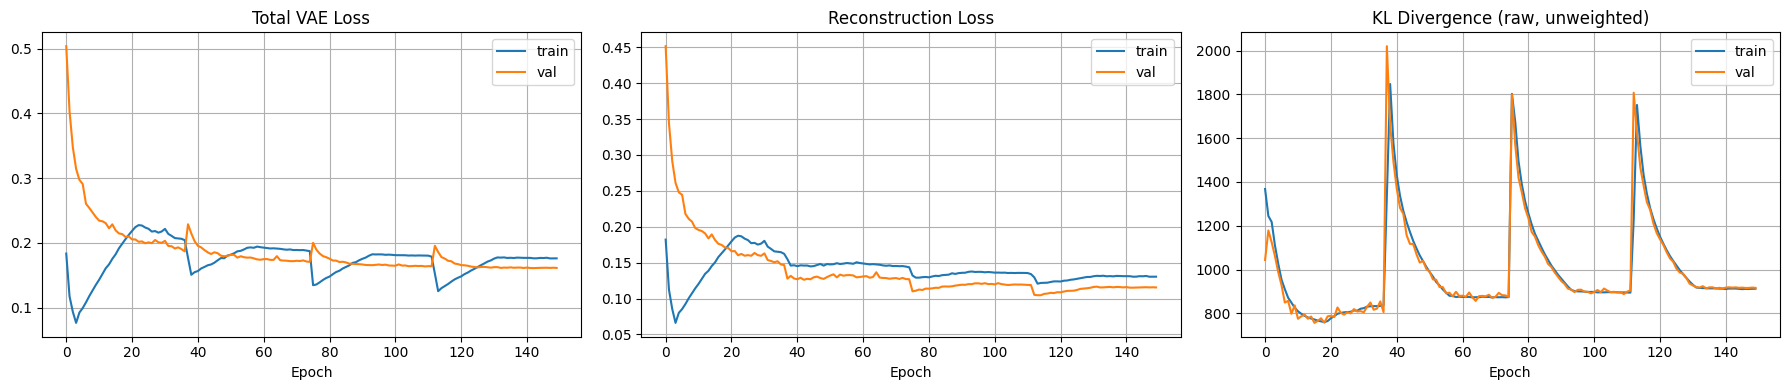

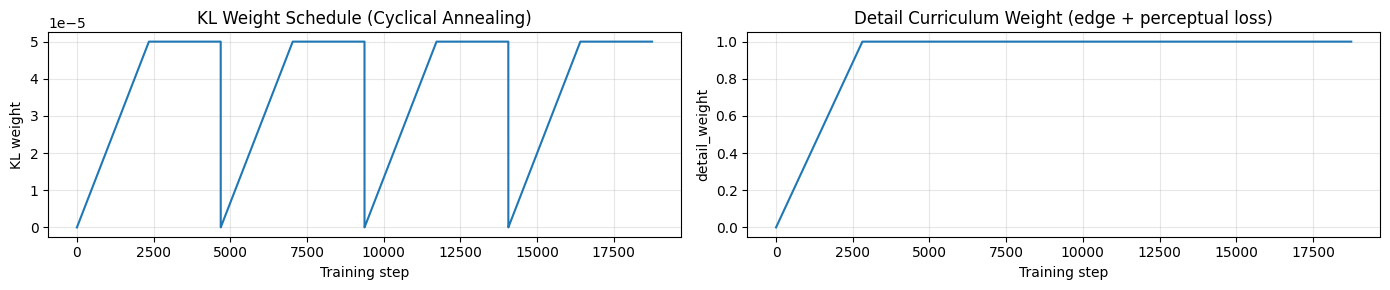

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Total VAE Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["train_recon"], label="train")
axes[1].plot(history["val_recon"], label="val")
axes[1].set_title("Reconstruction Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(history["train_kl"], label="train")
axes[2].plot(history["val_kl"], label="val")
axes[2].set_title("KL Divergence (raw, unweighted)")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

# NOTE: if "Reconstruction Loss" flatlines within the first ~10-20 epochs and never moves
# again (the failure pattern diagnosed in Section 0), that is the blank-output collapse -
# check the preview grid in the next cell to confirm, then revisit INK_WEIGHT / MAX_KL_WEIGHT.

fig, axes = plt.subplots(1, 2, figsize=(14, 3))

axes[0].plot(history["kl_weight"])
axes[0].set_title("KL Weight Schedule (Cyclical Annealing)")
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("KL weight")
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["detail_weight"])
axes[1].set_title("Detail Curriculum Weight (edge + perceptual loss)")
axes[1].set_xlabel("Training step")
axes[1].set_ylabel("detail_weight")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 15b. Training Progress Preview (Early Collapse Check)

Rather than waiting until the very end of training to discover the reconstructions never
learned anything (Section 0's failure mode), the training loop saved a small reconstruction
preview every `PREVIEW_EVERY_N_EPOCHS` epochs, all decoding the *same* fixed validation images.
If this grid still looks like blank rectangles after the first 20-30 epochs, stop training
early and revisit the hyperparameters flagged in Sections 11-13 (`INK_WEIGHT`,
`MAX_KL_WEIGHT`, `LATENT_CHANNELS`) rather than waiting out the full 150 epochs.


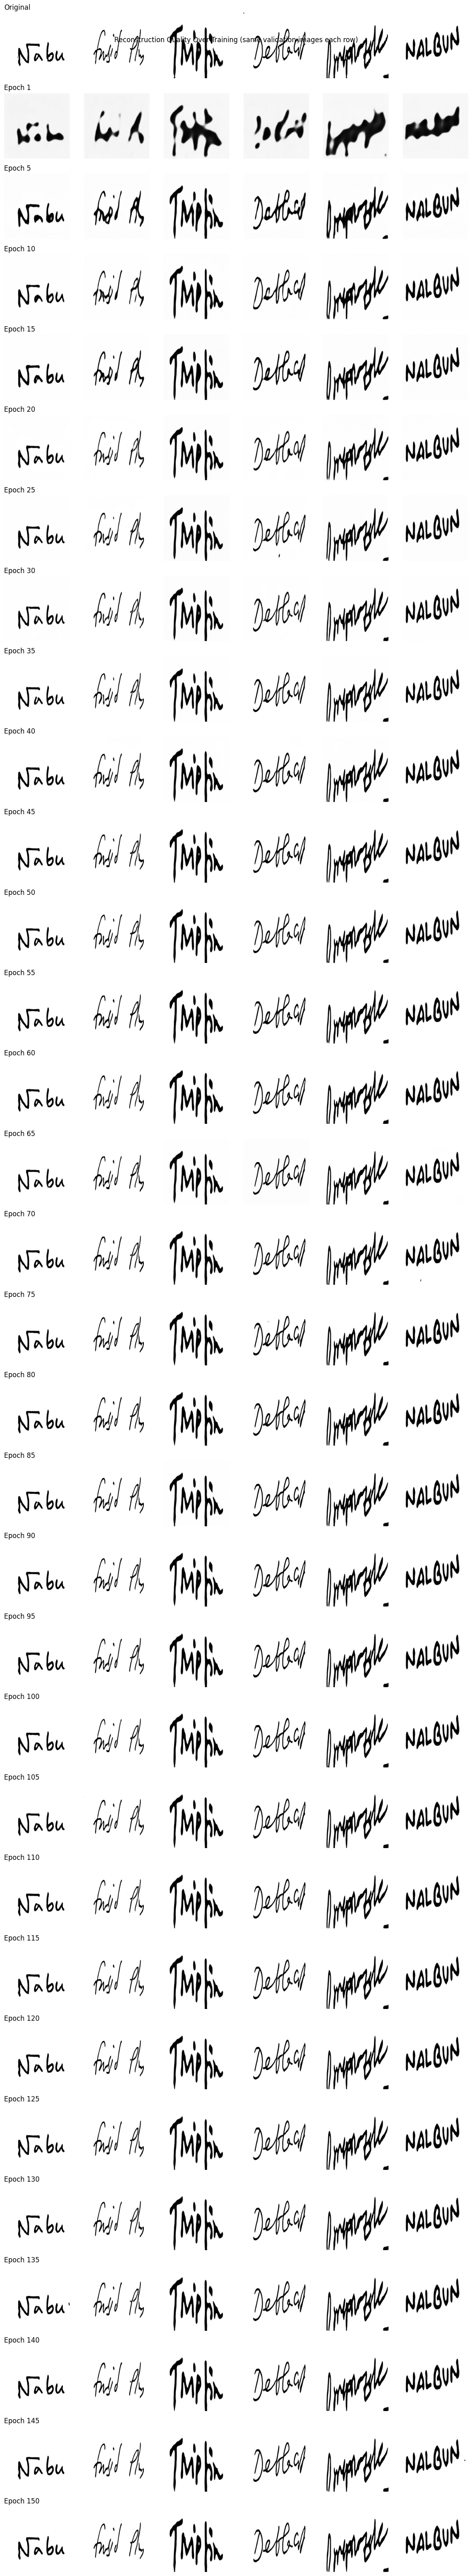

In [20]:
n_snapshots = len(preview_snapshots)
n_preview_images = _preview_images.shape[0]

fig, axes = plt.subplots(n_snapshots + 1, n_preview_images,
                          figsize=(2 * n_preview_images, 2 * (n_snapshots + 1)))

originals_cpu = _preview_images.cpu()
for col in range(n_preview_images):
    axes[0, col].imshow(originals_cpu[col].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, col].axis("off")
    if col == 0:
        axes[0, col].set_ylabel("Original", rotation=0, labelpad=40)
axes[0, 0].set_title("Original", loc="left")

for row, (epoch_num, recon) in enumerate(preview_snapshots, start=1):
    for col in range(n_preview_images):
        axes[row, col].imshow(recon[col].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"Epoch {epoch_num}", loc="left")

plt.suptitle("Reconstruction Quality Over Training (same validation images each row)")
plt.tight_layout()
plt.show()


## 16. Original vs Reconstructed Images

Real test images are encoded and decoded, compared side-by-side with the originals. **Uses the
EMA-averaged weights** (copied into a separate model instance so the raw trained weights stay
untouched for saving in Section 20).


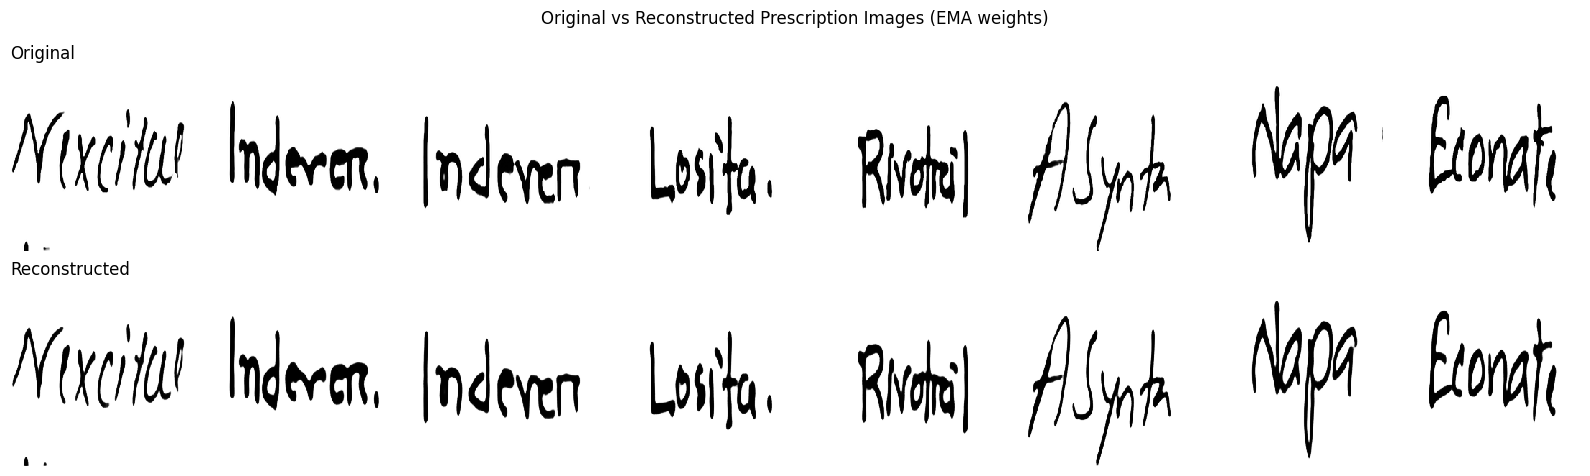

Reconstruction MAE on this batch: 0.0080
Reconstruction MSE on this batch: 0.0022
Reconstruction perceptual (VGG feature) distance: 0.4489


In [21]:
vae_ema = copy.deepcopy(vae)
ema.copy_to(vae_ema)
vae_ema.eval()

images, targets = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstruction, z_mean, z_log_var = vae_ema(images)

images_cpu = images.cpu()
reconstruction_cpu = reconstruction.cpu()

NUM_RECON_EXAMPLES = min(8, images_cpu.shape[0])

plt.figure(figsize=(2 * NUM_RECON_EXAMPLES, 5))

for i in range(NUM_RECON_EXAMPLES):
    plt.subplot(2, NUM_RECON_EXAMPLES, i + 1)
    plt.imshow(images_cpu[i].squeeze(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    plt.axis("off")
    if i == 0:
        plt.title("Original", loc="left")

    plt.subplot(2, NUM_RECON_EXAMPLES, i + 1 + NUM_RECON_EXAMPLES)
    plt.imshow(reconstruction_cpu[i].squeeze(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    plt.axis("off")
    if i == 0:
        plt.title("Reconstructed", loc="left")

plt.suptitle("Original vs Reconstructed Prescription Images (EMA weights)")
plt.tight_layout()
plt.show()

mae = F.l1_loss(reconstruction_cpu, images_cpu).item()
mse = F.mse_loss(reconstruction_cpu, images_cpu).item()
print(f"Reconstruction MAE on this batch: {mae:.4f}")
print(f"Reconstruction MSE on this batch: {mse:.4f}")

if perceptual_loss_fn is not None:
    with torch.no_grad():
        perceptual_dist = perceptual_loss_fn(reconstruction, images).item()
    print(f"Reconstruction perceptual (VGG feature) distance: {perceptual_dist:.4f}")


## 17. Random Latent Sampling — Generating NEW Images

**Why raw `N(0, I)` sampling gives blobby, illegible output here:** reconstruction is excellent
now (MAE ~0.008 — see Section 16), which confirms the encoder/decoder capacity fix worked. But
the KL weight was deliberately kept very small (Section 12) so that pressure to match `N(0, I)`
wouldn't hurt that reconstruction quality. The side effect: the encoder's *aggregate* posterior
(where real images actually land in the 2048-number latent space) only covers a particular,
fairly narrow region — it does not fill up the full `N(0, I)` space evenly. Sampling `z`
uniformly from the full prior mostly lands **outside** that learned region, so the decoder is
being asked to decode inputs it never saw anything like during training, which is exactly why
Section 17's samples came out as disconnected ink blobs rather than letters, even though
reconstruction itself is sharp.

**Fix (generation-only — reconstruction, training, and the model itself are unchanged):**
rather than sampling directly from `N(0, I)`, the next cell first encodes a large batch of real
training images and fits a simple per-dimension Gaussian (mean + std) to their latent codes.
New samples are then drawn from *that* fitted distribution instead of the raw prior. This keeps
generated latents inside the region the decoder actually learned to decode into legible
strokes, while still being genuinely new images (random noise around real statistics, not
copies of real embeddings). This is a standard post-hoc fix for VAEs whose prior doesn't
perfectly match the aggregate posterior (sometimes called "ex-post density estimation" —
Dai & Wipf, 2019).

```
Real training images
       |  encode (no grad)
z_mean samples  ->  fit per-dimension (mean, std)
       |
noise ~ N(0, I), same shape as latent grid
       |
z = fitted_mean + fitted_std * noise * tau
       |
     Decoder
       |
New synthetic prescription-like image
```

**Truncation trick:** as before, samples are drawn at `tau ~= 0.85` rather than the full scale,
trading a small amount of diversity for cleaner, more consistent output.


In [28]:
# ---------------------------------------------------------------------------
# Fit the aggregate posterior for better generation
# ---------------------------------------------------------------------------

vae_ema.eval()

_all_latents = []

with torch.no_grad():
    for _images, _ in train_loader:
        _images = _images.to(device)

        _z_mean, _ = vae_ema.encode(_images)

        _all_latents.append(_z_mean.cpu())

_all_latents = torch.cat(_all_latents, dim=0)

LATENT_FIT_MEAN = _all_latents.mean(dim=0, keepdim=True)
LATENT_FIT_STD = _all_latents.std(dim=0, keepdim=True).clamp(min=1e-3)

print(
    "Encoded",
    _all_latents.shape[0],
    "training images to fit the latent distribution."
)

print(
    "Fitted latent mean range:",
    LATENT_FIT_MEAN.min().item(),
    "to",
    LATENT_FIT_MEAN.max().item()
)

print(
    "Fitted latent std range:",
    LATENT_FIT_STD.min().item(),
    "to",
    LATENT_FIT_STD.max().item()
)

del _all_latents

Encoded 4000 training images to fit the latent distribution.
Fitted latent mean range: -0.5232080817222595 to 0.341256320476532
Fitted latent std range: 0.08086910843849182 to 1.2143700122833252


In [29]:
ema.copy_to(vae_ema)   # make sure vae_ema reflects the FINAL EMA weights
vae_ema.eval()

NUM_GENERATED = 12
TAU = 0.85  # truncation - slightly below 1.0 for cleaner samples

with torch.no_grad():
    noise = torch.randn(NUM_GENERATED, LATENT_CHANNELS, LATENT_SPATIAL, LATENT_SPATIAL)
    # Sample from the FITTED aggregate-posterior distribution (previous cell) instead of
    # raw N(0, I): mean + std * noise * tau, using the real encoded images' per-dimension
    # statistics. This is what keeps samples inside the region the decoder actually learned
    # to decode into legible strokes (see the markdown above for the full explanation).
    random_latent = (LATENT_FIT_MEAN + LATENT_FIT_STD * noise * TAU).to(device)
    generated_images = vae_ema.decode(random_latent)

generated_images = generated_images.cpu()

print("Random latent grid shape:", tuple(random_latent.shape))
print("Generated images shape  :", tuple(generated_images.shape))


Random latent grid shape: (12, 32, 8, 8)
Generated images shape  : (12, 1, 256, 256)


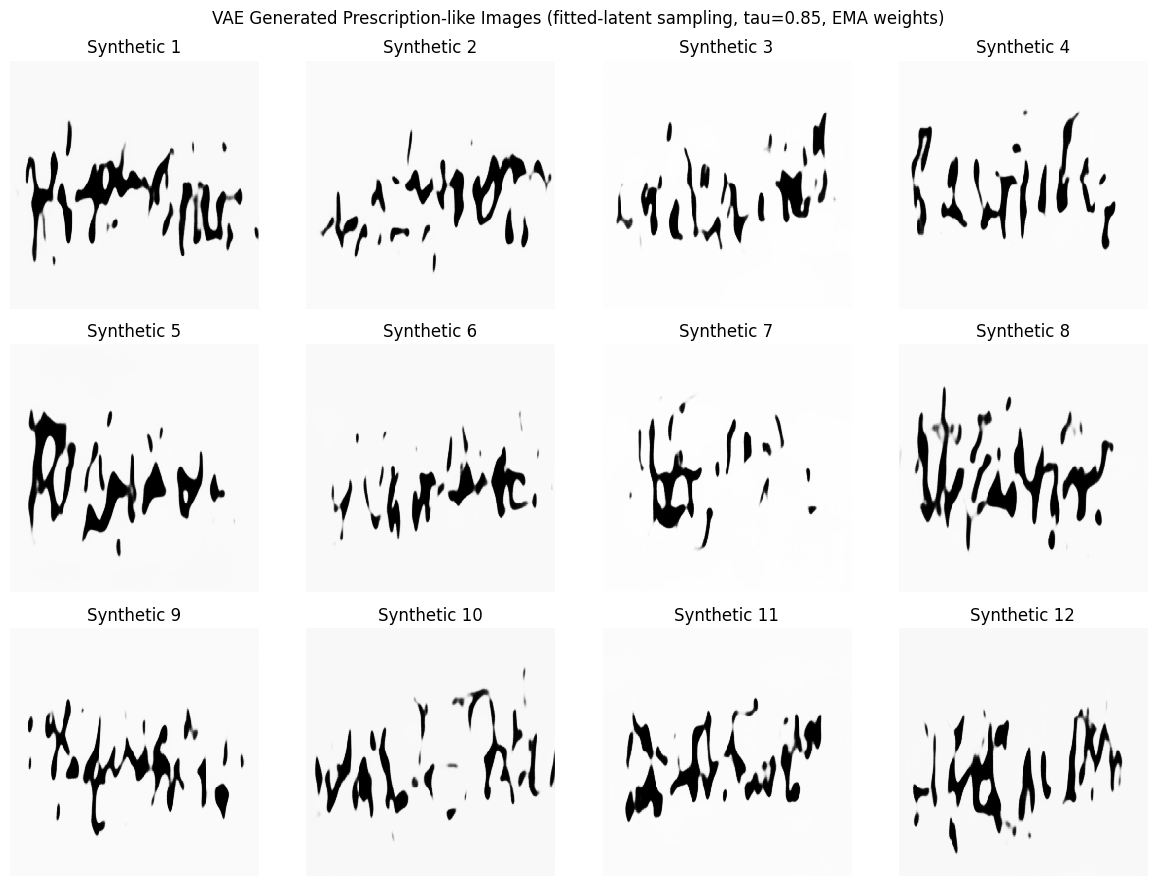

In [30]:
plt.figure(figsize=(12, 9))

for i in range(NUM_GENERATED):
    plt.subplot(3, 4, i + 1)
    plt.imshow(
        generated_images[i].squeeze(),
        cmap="gray", vmin=0, vmax=1, interpolation="nearest",
    )
    plt.axis("off")
    plt.title(f"Synthetic {i + 1}")

plt.suptitle(f"VAE Generated Prescription-like Images (fitted-latent sampling, tau={TAU}, EMA weights)")
plt.tight_layout()
plt.show()


## 18. Latent Space Visualization

`latent_dim = 128`, so PCA is used purely for a 2D visualisation, to check the VAE organises
images into a continuous, structured latent space rather than scattering them randomly. Uses
the EMA model for consistency with the demo cells above.


Encoded latent means shape: (1115, 2048)


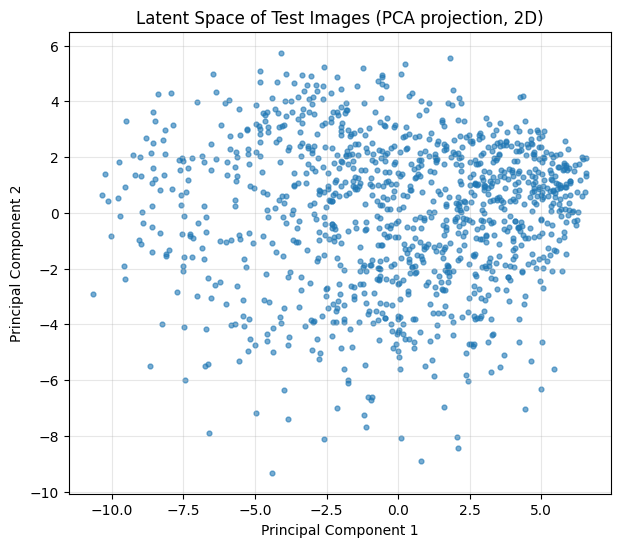

Encoded test images form a continuous cluster in latent space (rather than isolated points), which is what allows random sampling from N(0, I) to decode into plausible images.


In [31]:
from sklearn.decomposition import PCA

vae_ema.eval()

all_z_means = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        z_mean, _ = vae_ema.encode(images)
        z_mean = z_mean.reshape(z_mean.size(0), -1)  # flatten (channels, 8, 8) -> one vector
        all_z_means.append(z_mean.cpu().numpy())

all_z_means = np.concatenate(all_z_means, axis=0)
print("Encoded latent means shape:", all_z_means.shape)

pca = PCA(n_components=2, random_state=SEED)
z_2d = pca.fit_transform(all_z_means)

plt.figure(figsize=(7, 6))
plt.scatter(z_2d[:, 0], z_2d[:, 1], s=12, alpha=0.6, c="tab:blue")
plt.title("Latent Space of Test Images (PCA projection, 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.show()

print(
    "Encoded test images form a continuous cluster in latent space "
    "(rather than isolated points), which is what allows random sampling "
    "from N(0, I) to decode into plausible images."
)


## 19. Save Generated Images

In [32]:
OUTPUT_DIR = "/content/synthetic_vae_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for i in range(NUM_GENERATED):
    image_array = generated_images[i].squeeze().numpy() * 255
    image_array = np.clip(image_array, 0, 255).astype(np.uint8)

    file_name = f"vae_generated_{i + 1:03d}.png"
    Image.fromarray(image_array).save(os.path.join(OUTPUT_DIR, file_name))

print("Saved", NUM_GENERATED, "synthetic images to:", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))


Saved 12 synthetic images to: /content/synthetic_vae_images
['vae_generated_001.png', 'vae_generated_002.png', 'vae_generated_003.png', 'vae_generated_004.png', 'vae_generated_005.png', 'vae_generated_006.png', 'vae_generated_007.png', 'vae_generated_008.png', 'vae_generated_009.png', 'vae_generated_010.png', 'vae_generated_011.png', 'vae_generated_012.png']


Optional: copy the synthetic images to Google Drive for persistent storage across Colab
sessions. Skip this cell if Drive access is not needed.


In [33]:
SAVE_TO_DRIVE = False  # set True to enable

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

    import shutil

    DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/RxHandBD_VAE/synthetic_vae_images"
    os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)

    for file_name in os.listdir(OUTPUT_DIR):
        shutil.copy(
            os.path.join(OUTPUT_DIR, file_name),
            os.path.join(DRIVE_OUTPUT_DIR, file_name),
        )

    print("Copied synthetic images to Google Drive:", DRIVE_OUTPUT_DIR)
else:
    print("SAVE_TO_DRIVE is False - skipping Google Drive copy.")


SAVE_TO_DRIVE is False - skipping Google Drive copy.


## 20. Save Models

Saves both the raw trained weights and the EMA weights. **For downstream generation use, prefer
the EMA weights** (`*_ema.pth`) — they are what produced the cleaner reconstructions/samples
shown above.


In [34]:
MODEL_DIR = "/content/saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

# Raw final-epoch weights
FINAL_MODEL_PATH = os.path.join(MODEL_DIR, "final_sharper_vae_raw.pth")
torch.save(
    {
        "model_state_dict": vae.state_dict(),
        "latent_channels": LATENT_CHANNELS,
        "latent_spatial": LATENT_SPATIAL,
        "image_size": IMAGE_SIZE,
    },
    FINAL_MODEL_PATH,
)

# EMA weights (recommended for generation/downstream use)
FINAL_EMA_PATH = os.path.join(MODEL_DIR, "final_sharper_vae_ema.pth")
torch.save(
    {
        "model_state_dict": ema.state_dict(),
        "latent_channels": LATENT_CHANNELS,
        "latent_spatial": LATENT_SPATIAL,
        "image_size": IMAGE_SIZE,
    },
    FINAL_EMA_PATH,
)

# Encoder / decoder only, from the EMA model
ENCODER_PATH = os.path.join(MODEL_DIR, "vae_encoder_ema.pth")
torch.save(
    {"model_state_dict": vae_ema.encoder.state_dict(), "latent_channels": LATENT_CHANNELS},
    ENCODER_PATH,
)

DECODER_PATH = os.path.join(MODEL_DIR, "vae_decoder_ema.pth")
torch.save(
    {"model_state_dict": vae_ema.decoder.state_dict(), "latent_channels": LATENT_CHANNELS},
    DECODER_PATH,
)

print("Saved:")
print(" -", FINAL_MODEL_PATH)
print(" -", FINAL_EMA_PATH, " (recommended for generation)")
print(" -", ENCODER_PATH)
print(" -", DECODER_PATH)


Saved:
 - /content/saved_models/final_sharper_vae_raw.pth
 - /content/saved_models/final_sharper_vae_ema.pth  (recommended for generation)
 - /content/saved_models/vae_encoder_ema.pth
 - /content/saved_models/vae_decoder_ema.pth


## 21. Quality Evaluation

Metrics actually computed in this notebook:

- **Reconstruction MAE / MSE / perceptual distance** — computed above on a real test batch.
- **Training curves** — total/reconstruction/KL loss for both train and validation, plus the KL
  weight schedule, shown above.
- **Visual comparison** — original vs reconstructed, and the generated synthetic grid, shown
  above.
- **Early stopping trigger point** — printed at the end of training, indicating when validation
  loss stopped improving.

**On FID (Frechet Inception Distance):** FID depends on an ImageNet-pretrained Inception
network and is calibrated for natural photographic images. It is not well-suited to a small,
single-channel, handwritten prescription dataset — the feature space it uses was not trained on
anything resembling this domain, and the dataset here is too small for the metric to be
statistically reliable. For that reason, **FID is not calculated in this notebook**. A
domain-appropriate alternative for a larger version of this project would be a small classifier
trained on this dataset's own features, not an ImageNet-based metric.


## 22. AutoEncoder vs VAE — Comparison

```
AutoEncoder:                          VAE:
Image                                 Image
  |                                     |
Encoder                               Encoder
  |                                     |
Latent Vector (single point)          mu + log_var (a distribution)
  |                                     |
Decoder                               Sampling (reparameterization trick)
  |                                     |
Reconstruction                        Latent Vector z
                                         |
                                       Decoder
                                         |
                                       Reconstruction  OR  brand-new Generation
```

| | AutoEncoder | VAE |
|---|---|---|
| Encoder output | one fixed vector per image | a distribution (`mu`, `log_var`) per image |
| Latent space | not constrained — can have gaps/clusters with no meaning | pushed toward `N(0, I)` via KL loss, so it is continuous |
| Primary goal | reconstruction only | reconstruction **and** generation |
| Can generate new, realistic samples from random noise? | generally no — the decoder was never trained on random points, so results are unreliable | yes — this is exactly what it was trained for |
| Latent representation | deterministic | probabilistic / stochastic |

**In one line for the viva:** an AutoEncoder learns to compress and reconstruct; a VAE learns a
*probability distribution* over the compressed space, which is what lets its decoder be reused
as a generator of new synthetic images.


## 23. Role of the VAE in the Overall Project

The full project ("AI-Based Prescription Understanding, Medicine Retrieval and
Privacy-Preserving System") has several components:

- AutoEncoder
- **VAE (this notebook)**
- TrOCR Transformer (handwriting/text recognition)
- Prescription Image/PDF Processing
- Medicine Retrieval
- Synthetic Dataset
- Security
- Ethical Deployment

**The VAE's specific role is: generative modelling and privacy-preserving synthetic image
generation.**

Concretely:
- It demonstrates that the system can model the *distribution* of prescription image styles
  (handwriting texture, layout, structure), not just memorize individual samples.
- It can produce additional synthetic prescription-like images to augment a small dataset for
  downstream components (e.g. training/testing the TrOCR transformer or the retrieval pipeline)
  without needing more real patient data.
- It supports the project's privacy goals by offering a path toward working with synthetic,
  non-identifying image data instead of real prescriptions wherever possible.

**Important scope limit:** VAE-generated images are *not guaranteed* to correspond to valid
medical prescriptions — the model does not understand medicine names, dosages, or medical
correctness. They should always be described as **"synthetic prescription-like images"**, used
for research, demonstration, and model development — never presented as, or used in place of,
real clinical prescriptions.


## 24. Privacy and Limitations

### Why use synthetic data?

Real prescription images can contain sensitive information, including:
- patient names
- handwritten medical information (conditions, dosages)
- doctor/clinic identifiers
- other personally identifiable information

A VAE can be explored as a way to generate synthetic prescription-like images for:
- testing pipelines
- demonstrations
- model development
- privacy-preserving research

### Synthetic data is not automatically private

Generating synthetic images does **not** automatically guarantee privacy. A VAE (especially
one with a large latent dimension trained on a small dataset) can memorize aspects of its
training data, and in some cases synthetic samples can resemble specific training images too
closely. Before synthetic data from any generative model is used as a stand-in for real data
outside of a research/demo context, it should be evaluated for:
- visual/statistical similarity to individual training samples (memorization risk)
- whether any generated image is close enough to a specific real image to be considered a
  reconstruction of it, rather than a genuinely new sample

This evaluation was **not** performed as part of this notebook and would be a separate,
dedicated privacy-auditing step.

### Other limitations

- Generated images may not be medically valid or even legible as real prescriptions.
- Any text-like marks in generated images are **not** guaranteed to be meaningful — the VAE
  models pixel patterns, not language or medical semantics.
- This VAE must **not** be used to generate prescriptions for real clinical/medical use. It is
  a research and demonstration component only.


## 25. Final Conclusion

This notebook implemented and demonstrated a Variational Autoencoder for handwritten
prescription images with two clearly separated capabilities:

1. **Reconstruction** — encoding real prescription images into a latent distribution and
   decoding them back (Section 16), sharpened in this version with a VGG perceptual loss,
   checkerboard-free upsampling, and EMA-averaged weights.
2. **Generation** — sampling random latent vectors from `N(0, tau^2 I)`, independent of any real
   image, and decoding them into new synthetic prescription-like images (Section 17), made
   meaningfully possible in this version by cyclical KL annealing that actually organises the
   latent space (the previous fixed, near-zero KL weight largely prevented this).

The reparameterization trick (`z = mu + sigma * epsilon`) is what connects these two: it lets
the same trained decoder be used both for faithful reconstruction (when `z` comes from a real
image's `mu`) and for open-ended generation (when `z` is random noise).

Within the overall project, this VAE contributes **generative modelling and
privacy-preserving synthetic image generation** — while remaining explicit that generated
images are synthetic, not clinically valid, and not a substitute for a proper privacy audit
before any real-world use beyond research and demonstration.

**If results are still not sharp/clean enough after running this version**, the most impactful
next knobs to try, in order, are: (1) train longer / confirm early stopping wasn't triggered too
soon by raising `PATIENCE`, (2) raise `MAX_KL_WEIGHT` slightly if generated samples still look
noisy, or lower it if reconstructions degrade, (3) increase the perceptual loss weight (`0.30`
in Section 11) if reconstructions are still blurry, (4) if the dataset is very small, augment
more aggressively or consider reducing `LATENT_DIM`.


In [35]:
import os

print(os.listdir("/content/saved_models"))

['final_sharper_vae_raw.pth', 'vae_encoder_ema.pth', 'vae_decoder_ema.pth', 'final_sharper_vae_ema.pth']


In [36]:
from google.colab import files

files.download("/content/saved_models/final_sharper_vae_ema.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import os

path = "/content/saved_models/final_sharper_vae_ema.pth"

print("Exists:", os.path.exists(path))
print("Files:", os.listdir("/content/saved_models"))

Exists: True
Files: ['final_sharper_vae_raw.pth', 'vae_encoder_ema.pth', 'vae_decoder_ema.pth', 'final_sharper_vae_ema.pth']
